# Логістична регресія: тяжкість ДТП (`Severity`)

Дані — результат `classification_data_preparation.ipynb` (`data/processed/classification/`): ознаки вже очищені, закодовані й масштабовані, ціль `label` (0…3 = Severity 1…4), ваги класів `w_bal`.

**План:**
1. Завантажити train / valid / test.
2. Baseline — завжди найчастіший клас (`DummyClassifier`).
3. `LogisticRegression` (мультиноміальна) у двох режимах, обраних у дослідженні:
   * **A — без ваг + пороги рішення, підібрані на valid** → найкращий баланс помилок (macro-F1);
   * **B — балансувальні ваги класів** → максимальний recall рідкісних (тяжких) класів.
4. Метрики на valid / test (+ train для перевірки перенавчання), матриці помилок, коефіцієнти, збереження моделей.

Бібліотека — scikit-learn: Spark на Windows без `winutils.exe` не читає parquet, а готові дані — звичайні parquet-файли.

## 1. Завантаження даних

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pyarrow.parquet as pq
from sklearn.exceptions import ConvergenceWarning

TASK = "classification"
SEED = 42
DATA_DIR = PROJECT_ROOT / "data" / "processed" / TASK
MODELS_DIR = PROJECT_ROOT / "data" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

meta = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
FEATURES = meta["feature_names"]
TARGETS = ('Log_Duration', 'Duration_Minutes') if TASK == "regression" else ('label', 'w_bal')


def load(split, dtype):
    # Ознаки — numpy-матриця потрібного типу (заповнюється частинами, без зайвих копій); цілі — pandas
    files = sorted((DATA_DIR / split).glob("part-*.parquet"))
    n = sum(pq.ParquetFile(f).metadata.num_rows for f in files)
    X = np.empty((n, len(FEATURES)), dtype=dtype)
    targets, pos = [], 0
    for f in files:
        part = pd.read_parquet(f, columns=FEATURES + sorted(TARGETS))
        X[pos:pos + len(part)] = part[FEATURES].to_numpy(dtype=dtype)
        targets.append(part[sorted(TARGETS)])
        pos += len(part)
    return X, pd.concat(targets, ignore_index=True)


t0 = time.time()
X_train, t_train = load("train", np.float64)
if TASK == "classification":
    X_valid, t_valid = load("valid", np.float32)
    X_test, t_test = load("test", np.float32)
    print(f"train {X_train.shape}, valid {X_valid.shape}, test {X_test.shape} — {time.time() - t0:.0f} c")
else:
    print(f"train {X_train.shape} — {time.time() - t0:.0f} c (valid / test завантажуються після навчання, щоб зменшити пікове використання пам'яті)")

train (4789382, 235), valid (683877, 235), test (1366450, 235) — 14 c


## 2. Моделі

**Baseline:** `DummyClassifier(strategy="most_frequent")` — завжди клас 2.

**`LogisticRegression`** (мультиноміальна, `lbfgs`, стандартна L2-регуляризація `C = 1`): при ~4.8 млн записів і 235 ознаках регуляризація практично не впливає на коефіцієнти, але покращує збіжність оптимізатора.

* **A — без ваг класів.** Модель оцінює реальні ймовірності класів; поріг рішення потім зсуваємо на valid (розділ 3).
* **B — `class_weight="balanced"`** ($w_c = N / (K\,n_c)$, ті самі значення, що й колонка `w_bal`): кожен клас дає однаковий внесок у функцію втрат → модель частіше прогнозує рідкісні класи.

Матриця train у float64 (≈9 ГБ): оптимізатор `lbfgs` у scikit-learn працює в подвійній точності.

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

y_train, y_valid, y_test = (t["label"].to_numpy().astype(int) for t in (t_train, t_valid, t_test))
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

models, fit_info = {}, {}
for name, params in [("A. без ваг", {}), ("B. ваги класів", {"class_weight": "balanced"})]:
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        models[name] = LogisticRegression(max_iter=300, tol=1e-4, **params).fit(X_train, y_train)
    fit_info[name] = {"секунд": round(time.time() - t0), "ітерацій": int(models[name].n_iter_[0])}
    print(f"{name}: {fit_info[name]}")

A. без ваг: {'секунд': 371, 'ітерацій': 231}


B. ваги класів: {'секунд': 356, 'ітерацій': 215}


## 3. Пороги рішення для моделі A (на valid)

Звичайне правило «клас з найбільшою ймовірністю» при сильному дисбалансі майже не обирає рідкісні класи. Для мультикласової задачі поріг задається зсувами: $\hat y = \arg\max_k (\log p_k + b_k)$. Зсуви $b_k$ підбираємо **на valid** так, щоб максимізувати macro-F1 (покоординатний пошук по сітці; зсув класу 2 фіксований, бо важливі лише різниці). Test у підборі не бере участі.

Готової бібліотечної функції для мультикласових порогів немає: `sklearn.model_selection.TunedThresholdClassifierCV` працює лише для бінарної класифікації. Тому пошук — кілька рядків numpy, а метрика — `sklearn.metrics.f1_score`.

In [3]:
from sklearn.metrics import f1_score


def predict_with_offsets(proba, offsets):
    return np.argmax(np.log(proba + 1e-12) + offsets, axis=1)


def tune_offsets(proba, y, ref=1, grid=np.linspace(-4, 4, 81), rounds=3):
    offsets = np.zeros(proba.shape[1])
    best = f1_score(y, predict_with_offsets(proba, offsets), average="macro")
    for _ in range(rounds):
        for k in range(proba.shape[1]):
            if k == ref:
                continue
            for g in grid:
                trial = offsets.copy()
                trial[k] = g
                score = f1_score(y, predict_with_offsets(proba, trial), average="macro")
                if score > best:
                    best, offsets = score, trial
    return offsets, best


proba_valid_A = models["A. без ваг"].predict_proba(X_valid)
t0 = time.time()
OFFSETS, valid_f1 = tune_offsets(proba_valid_A, y_valid)
print(f"Пошук зсувів: {time.time() - t0:.0f} c")
print(f"macro-F1 на valid: без зсувів {f1_score(y_valid, proba_valid_A.argmax(1), average='macro'):.4f} → зі зсувами {valid_f1:.4f}")
pd.Series(OFFSETS, index=[f"Severity {c}" for c in [1, 2, 3, 4]], name="зсув log-ймовірності").round(2).to_frame().T

Пошук зсувів: 77 c
macro-F1 на valid: без зсувів 0.6480 → зі зсувами 0.6833


,Severity 1,Severity 2,Severity 3,Severity 4
зсув log-ймовірності,0.6,0.0,0.4,1.2


## 4. Якість

* **macro-F1** — середнє F1 по класах, кожен клас важить однаково → головна метрика при дисбалансі;
* **balanced accuracy** — середній recall по класах;
* **accuracy** — для довідки: «завжди клас 2» вже дає ~78%;
* per-class precision / recall — особливо для рідкісних класів 1 і 4.

In [4]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support


def summary(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2, 3], zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "balanced accuracy": balanced_accuracy_score(y, pred),
            "macro-F1": f1_score(y, pred, average="macro"), "weighted-F1": f1_score(y, pred, average="weighted"),
            **{f"recall {c}": r[i] for i, c in enumerate([1, 2, 3, 4])},
            **{f"precision {c}": p[i] for i, c in enumerate([1, 2, 3, 4])}}


preds = {}
for split, X, y in [("valid", X_valid, y_valid), ("test", X_test, y_test)]:
    pA = models["A. без ваг"].predict_proba(X)
    preds[("Baseline (клас 2)", split)] = baseline.predict(X)
    preds[("A. без ваг", split)] = pA.argmax(1)
    preds[("A. без ваг + пороги", split)] = predict_with_offsets(pA, OFFSETS)
    preds[("B. ваги класів", split)] = models["B. ваги класів"].predict(X)
y_by_split = {"valid": y_valid, "test": y_test}
results = pd.DataFrame({k: summary(y_by_split[k[1]], v) for k, v in preds.items()}).T
results.index.names = ["модель", "вибірка"]
results.xs("test", level="вибірка").round(4)

,accuracy,balanced accuracy,macro-F1,weighted-F1,recall 1,recall 2,recall 3,recall 4,precision 1,precision 2,precision 3,precision 4
модель,,,,,,,,,,,,
Baseline (клас 2),0.7853,0.2500,0.2199,0.6909,0.0000,1.0000,0.0000,0.0000,0.0000,0.7853,0.0000,0.0000
A. без ваг,0.8925,0.5922,0.6471,0.8857,0.4542,0.9555,0.7344,0.2246,0.7270,0.9164,0.7953,0.6229
A. без ваг + пороги,0.8868,0.6824,0.6815,0.8872,0.6037,0.9282,0.7881,0.4098,0.6141,0.9361,0.7584,0.4144
B. ваги класів,0.7451,0.8203,0.5260,0.7924,0.9538,0.7243,0.8205,0.7827,0.1857,0.9757,0.6502,0.1391


In [5]:
# Перевірка перенавчання: macro-F1 на train ≈ valid ≈ test?
train_pred = predict_with_offsets(models["A. без ваг"].predict_proba(X_train), OFFSETS)
overfit = pd.DataFrame({
    "train": [f1_score(y_train, train_pred, average="macro"),
              f1_score(y_train, models["B. ваги класів"].predict(X_train), average="macro")],
    "valid": [results.loc[("A. без ваг + пороги", "valid"), "macro-F1"], results.loc[("B. ваги класів", "valid"), "macro-F1"]],
    "test": [results.loc[("A. без ваг + пороги", "test"), "macro-F1"], results.loc[("B. ваги класів", "test"), "macro-F1"]],
}, index=["A. без ваг + пороги", "B. ваги класів"])
overfit.round(4)

,train,valid,test
A. без ваг + пороги,0.6810,0.6833,0.6815
B. ваги класів,0.5265,0.5258,0.5260


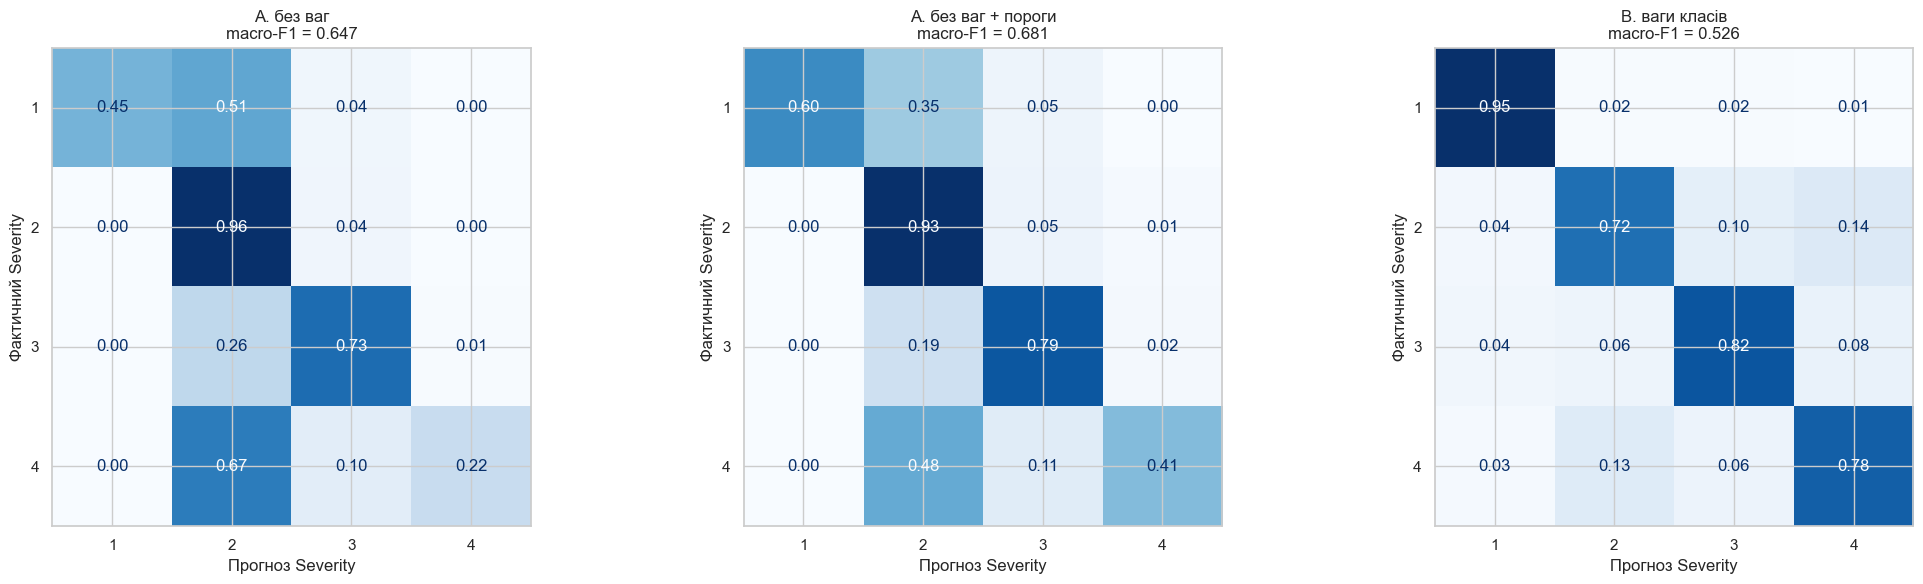

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, name in zip(axes, ["A. без ваг", "A. без ваг + пороги", "B. ваги класів"]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[(name, "test")], normalize="true", values_format=".2f",
                                            display_labels=[1, 2, 3, 4], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nmacro-F1 = {results.loc[(name, 'test'), 'macro-F1']:.3f}")
    ax.set_xlabel("Прогноз Severity")
    ax.set_ylabel("Фактичний Severity")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.metrics import classification_report

print("A. без ваг + пороги (test):")
print(classification_report(y_test, preds[("A. без ваг + пороги", "test")], target_names=[f"Severity {c}" for c in [1, 2, 3, 4]], digits=3))
print("B. ваги класів (test):")
print(classification_report(y_test, preds[("B. ваги класів", "test")], target_names=[f"Severity {c}" for c in [1, 2, 3, 4]], digits=3))

A. без ваг + пороги (test):


              precision    recall  f1-score   support

  Severity 1      0.614     0.604     0.609     12064
  Severity 2      0.936     0.928     0.932   1073109
  Severity 3      0.758     0.788     0.773    246235
  Severity 4      0.414     0.410     0.412     35042

    accuracy                          0.887   1366450
   macro avg      0.681     0.682     0.681   1366450
weighted avg      0.888     0.887     0.887   1366450

B. ваги класів (test):


              precision    recall  f1-score   support

  Severity 1      0.186     0.954     0.311     12064
  Severity 2      0.976     0.724     0.831   1073109
  Severity 3      0.650     0.821     0.726    246235
  Severity 4      0.139     0.783     0.236     35042

    accuracy                          0.745   1366450
   macro avg      0.488     0.820     0.526   1366450
weighted avg      0.889     0.745     0.792   1366450



## 5. Коефіцієнти

Для мультиноміальної моделі кожен клас має власний вектор коефіцієнтів. Показуємо, які ознаки найсильніше зсувають прогноз **до класу 4** (тяжкі ДТП) порівняно з рештою класів: різниця коефіцієнта класу 4 і середнього коефіцієнта інших класів.

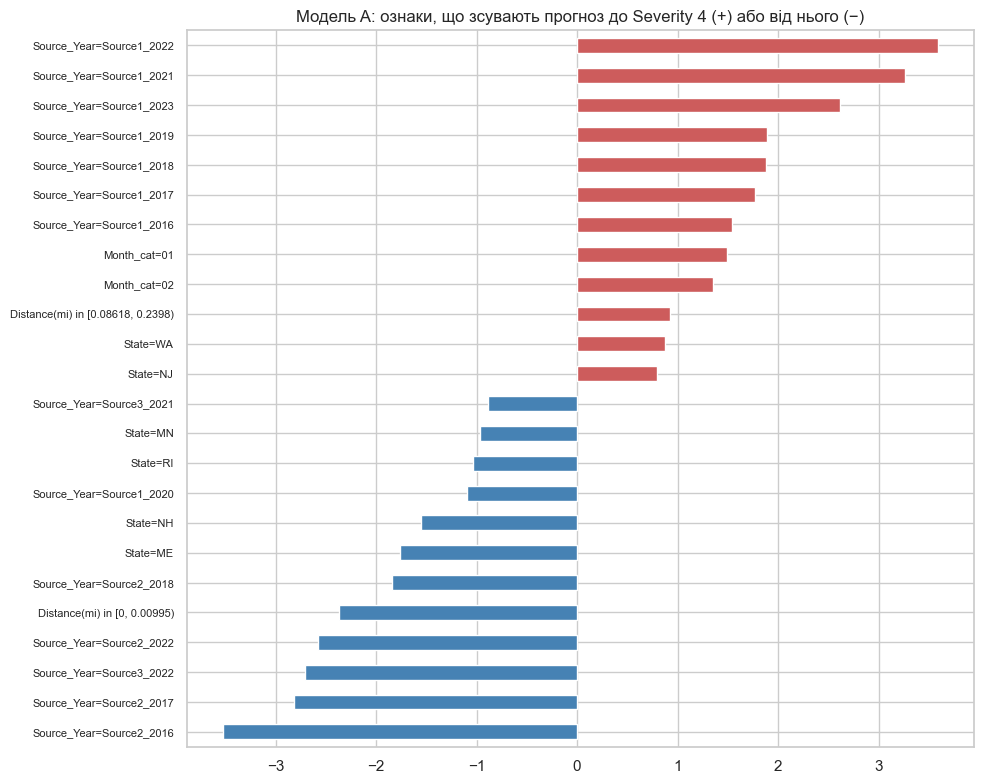

In [8]:
coef = pd.DataFrame(models["A. без ваг"].coef_.T, index=FEATURES, columns=[f"Severity {c}" for c in [1, 2, 3, 4]])
contrast = (coef["Severity 4"] - coef.drop(columns="Severity 4").mean(axis=1)).sort_values()
top = pd.concat([contrast.head(12), contrast.tail(12)])
fig, ax = plt.subplots(figsize=(10, 8))
top.plot.barh(ax=ax, color=["steelblue" if v < 0 else "indianred" for v in top])
ax.set_title("Модель A: ознаки, що зсувають прогноз до Severity 4 (+) або від нього (−)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [9]:
joblib.dump({"model": models["A. без ваг"], "decision_log_offsets": OFFSETS, "features": FEATURES,
             "classes": "label 0..3 = Severity 1..4"}, MODELS_DIR / "classification_logreg_thresholds.joblib")
joblib.dump({"model": models["B. ваги класів"], "features": FEATURES, "classes": "label 0..3 = Severity 1..4"},
            MODELS_DIR / "classification_logreg_balanced.joblib")
print("Збережено:", sorted(p.name for p in MODELS_DIR.glob("classification_*.joblib")))

Збережено: ['classification_logreg_balanced.joblib', 'classification_logreg_thresholds.joblib']


## Висновки

| Модель (test) | Accuracy | Balanced acc. | **Macro-F1** | Recall 1 / 4 | Precision 1 / 4 |
|---|---|---|---|---|---|
| Baseline — завжди клас 2 | 0.785 | 0.250 | 0.220 | 0 / 0 | — |
| A. без ваг | 0.893 | 0.592 | 0.647 | 0.45 / 0.22 | 0.73 / 0.62 |
| **A. без ваг + пороги з valid** | **0.887** | 0.682 | **0.681** | 0.60 / 0.41 | 0.61 / 0.41 |
| B. ваги класів | 0.745 | **0.820** | 0.526 | **0.95 / 0.78** | 0.19 / 0.14 |

* **Найкращий загальний баланс помилок — модель A з порогами** (macro-F1 **0.681**, у 3 рази краще за baseline): F1 по класах 0.61 / 0.93 / 0.77 / 0.41. Пороги, підібрані на valid, піднімають macro-F1 з 0.647 до 0.681 переважно за рахунок рідкісних класів (recall класу 4: 0.22 → 0.41).
* **Модель B (ваги класів)** знаходить 95% ДТП класу 1 і 78% — класу 4 (balanced accuracy 0.82), але ціною частих хибних тривог (precision 0.19 і 0.14). Її варто обирати, якщо пропустити тяжку ДТП гірше, ніж перевірити зайву.
* **Перенавчання немає:** macro-F1 на train / valid / test — 0.681 / 0.683 / 0.682 (A) і 0.527 / 0.526 / 0.526 (B). Оптимізатор зійшовся (231 і 215 ітерацій із 300).
* **Найслабше місце — клас 4:** 48% таких ДТП модель A відносить до класу 2. У Source1 класи 2 і 4 відрізняються фактичним впливом на рух (перекриттям), якого серед ознак на момент ДТП немає — це межа для будь-якої моделі на цих ознаках.
* Обидві моделі — та сама логістична регресія; різниця лише в тому, як враховується дисбаланс. Вибір між ними — це вибір робочої точки precision ↔ recall під конкретну мету.

**Нові дані: невідомий рік джерела.** `Source_Year` — найсильніша ознака, і вона прив'язана до років train. Перевірка «на майбутньому» (модель навчена **без 2023 р.**, оцінка на 42 167 test-записах `Source1_2023`):

| Сценарій | Accuracy | F1 класу 4 | % прогнозів класу 3 |
|---|---|---|---|
| рік був у навчанні (поточна модель) | 0.969 | 0.324 | 0% |
| невідомий рік → референсна категорія (усі `Source_Year` = 0) | 0.744 | 0.366 | 21% |
| **невідомий рік → останній рік того ж джерела** | **0.969** | 0.311 | 0% |

Тому правило для нових даних: **невідомий `Source_Year` замінюється на останній відомий рік того ж джерела** (`Source1_2023`, `Source2_2022`, `Source3_2022`; див. `metadata.json` → `unseen_source_year`). Воно працює, лише поки джерело не змінює схему розмітки (Source1 змінив її у 2021 р. — класи 1 і 3 зникли), тож на нових даних потрібні моніторинг розподілу прогнозів і періодичне перенавчання.

**Що могло б покращити якість:** нелінійні моделі (градієнтний бустинг); перевірка чутливості до правила розв'язання суперечливих знімків (максимальна тяжкість vs видалення).

Моделі збережено: `data/models/classification_logreg_thresholds.joblib` (модель A + зсуви порогів; прогноз — `argmax(log p + offsets)`) і `data/models/classification_logreg_balanced.joblib` (модель B).